# ***supervised learning***

This notebook aims to compare common supervised learning models by training each model on the Breast Cancer dataset and comparing their prediction accuracies using a table and a graph.

aryam yousef alharbi                  
id:4551244





In [ ]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt



## uploading and exploring data  

In [ ]:
cancer=load_breast_cancer()
#exploring the data
cancer.feature_names

data=pd.DataFrame(cancer.data, columns=cancer.feature_names )

print(cancer.feature_names)
print(cancer.target)
data.head()

In [ ]:
x=cancer.data
y=cancer.target
print("x shape:",x.shape)
print("y shape:",y.shape)

In [ ]:
x_train, x_test, y_train, y_test=train_test_split(x,y,test_size=0.25,random_state=42, stratify=y)
print("Training features:", x_train.shape)
print("Test features:", x_test.shape)
print("Training labels:", y_train.shape)
print("Test labels:", y_test.shape)

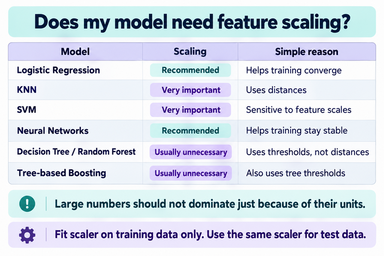

In [ ]:
scaler=StandardScaler()
# Learn each feature's mean and standard deviation from training data,
# then use them to scale the training data.
x_trainscaled= scaler.fit_transform(x_train)
# Scale test data using the SAME training means and standard deviations.
x_testscaled=scaler.transform(x_test)

### Logistic Regression

Logistic Regression estimates the probability that a sample belongs to a class, then uses it to make a prediction.

- **`max_iter`:** maximum number of training iterations. Increasing it gives the model more time to converge.

In [ ]:
log_model=LogisticRegression(max_iter=1000)
log_model.fit(x_trainscaled,y_train)
log_prediction=log_model.predict(x_testscaled)
output=pd.DataFrame(
    {
        "Actual": pd.Series(y_test).map({0:"malignant",1:"benign"}),
        "Predicted":pd.Series(log_prediction).map({0:"malignant",1:"benign"})
        })
output['correct']=output['Actual']==output['Predicted']
output.head(20)

results of  Logistic Regression

In [ ]:
log_accurasy=accuracy_score(y_test,log_prediction)
confusion_matrix_log= pd.DataFrame(confusion_matrix(y_test,log_prediction),columns=["malignant",'benign'],index=["malignant",'benign'])
print(confusion_matrix_log)
print(f'log_accurasy:{log_accurasy}')
#.sum() counts True as 1 and False as 0.
print('correct',output['correct'].sum())
#~ flips True and False
print('wrong',(~output['correct']).sum())

### K-Nearest Neighbors (KNN)

KNN classifies a sample using the majority class among its nearest training samples.

- **`n_neighbors`:** number of neighbors considered. Smaller values capture more detail but may overfit; larger values create smoother boundaries.

In [ ]:
knn_model=KNeighborsClassifier(n_neighbors=5)
knn_model.fit(x_trainscaled,y_train)
knn_prediction=knn_model.predict(x_testscaled)
confusion_matrix_knn= pd.DataFrame(confusion_matrix(y_test,knn_prediction),columns=["malignant",'benign'],index=["malignant",'benign'])
print(confusion_matrixnp)
knn_accurasy=accuracy_score(y_test,knn_prediction)
print(f'knn_accurasy{knn_accurasy}')

### Gaussian Naive Bayes

Gaussian Naive Bayes predicts the most likely class using probabilities. It assumes features are independent within each class and follow a normal distribution.

- **`GaussianNB()`:** uses the default settings in this notebook.

In [ ]:
model_nb= GaussianNB()
model_nb.fit(x_trainscaled,y_train)
model_nb_prediction=model_np.predict(x_testscaled)
#model_np.predict_proba(x_testscaled)

result of naive bayse


In [ ]:
confusion_matrixnb= pd.DataFrame(confusion_matrix(y_test,model_nb_prediction),columns=["malignant",'benign'],index=["malignant",'benign'])
print(confusion_matrixnb)
nb_accurasy=accuracy_score(y_test,model_nb_prediction)
print(f'nb_accurasy{nb_accurasy}')

### Decision Tree

A Decision Tree classifies samples through a series of feature-based questions, such as “Is this value greater than a threshold?”

- **`max_depth`:** maximum tree depth. Deeper trees capture more detail but may overfit.
- **`random_state`:** makes the model’s random choices reproducible.

In [ ]:
model_tree=DecisionTreeClassifier(max_depth=5,random_state=6)
model_tree.fit(x_trainscaled,y_train)
model_tree_predction=model_tree.predict(x_testscaled)
model_tree_score=accuracy_score(y_test,model_tree_predction)
confusion_matrix_tree= pd.DataFrame(confusion_matrix(y_test,model_tree_predction),columns=["malignant",'benign'],index=["malignant",'benign'])
print(confusion_matrix_tree)
print(f'model_tree_score:{model_tree_score}')



### Decision Tree

A Decision Tree classifies samples through a series of feature-based questions, such as “Is this value greater than a threshold?”

- **`max_depth`:** maximum tree depth. Deeper trees capture more detail but may overfit.
- **`random_state`:** makes the model’s random choices reproducible.

In [ ]:
model_rfc=RandomForestClassifier(n_estimators=100,max_depth=5,random_state=6)
model_rfc.fit(x_train,y_train)
model_rfc_predction=model_rfc.predict(x_test)
model_rfc_score=accuracy_score(y_test,model_rfc_predction)
confusion_matrix_rfc= pd.DataFrame(confusion_matrix(y_test,model_rfc_predction),columns=["malignant",'benign'],index=["malignant",'benign'])
print(confusion_matrix_rfc)
print(f'rfc_score : {model_rfc_score}')

### Support Vector Machine (SVM)

SVM finds a boundary between classes with the widest possible margin. **Support vectors** are the training points that determine this boundary.

- **`kernel`:** boundary type—`linear` for a straight boundary, `rbf` for a flexible, curved boundary.
- **`C`:** penalty for training errors. Larger values prioritize fewer training errors; smaller values allow more errors with stronger regularization.
- **`gamma`:** how locally each point influences the RBF boundary. Larger values create more detailed boundaries; smaller values create smoother boundaries.

Large `C` or `gamma` values may cause overfitting.

In [ ]:
svm_model=SVC(kernel='rbf',C=1, gamma="scale")
svm_model.fit(x_trainscaled,y_train)
svm_prediction=svm_model.predict(x_testscaled)
svm_score=accuracy_score(y_test,svm_prediction)
confusion_matrix_svm= pd.DataFrame(confusion_matrix(y_test,svm_prediction),columns=["malignant",'benign'],index=["malignant",'benign'])
print(confusion_matrix_svm)
print(f'svm_score : {svm_score}')

# ***Models Accuracy Comparison***





In [ ]:
accurasy_all_model=np.round(np.array([log_accurasy,knn_accurasy,nb_accurasy,model_tree_score,model_rfc_score,svm_score]),2)
accurasy_all_model

Comparison_df=pd.DataFrame({'model':['LR', 'KNN', 'NB', 'DT', 'RF', 'SVM'],
              'Accuracy':accurasy_all_model})



In [ ]:
import matplotlib.pyplot as plt

# Draw a bar for each model.
plt.bar(Comparison_df['model'], Comparison_df['Accuracy'])

# Label each bar with its accuracy.
for i, score in enumerate(Comparison_df['Accuracy']):
    plt.text(i, score, score, ha='center', va='bottom')

# Zoom in to show the differences clearly.
plt.ylim(Comparison_df['Accuracy'].min() - 0.02, 1.03)

plt.title('Models Accuracy' )
plt.ylabel('Accuracy')
plt.show()
